# Measuring the temperature of the CMB

## Introduction to Radio Astronomy - Report 2

### Srishti Bendigeri
### s5511178

power given to 7 decimal places - let's put everything to 7 d.p.s

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.pyplot import figure,show
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths

In [2]:
data_set1 = np.loadtxt(f'dataset1.txt',comments="#")
ang_set1_deg = np.array(data_set1[:,0]) #slicing syntax to get the first column
ang_set1 = ang_set1_deg - 90
P_set1_dBm = np.array(data_set1[:,1]) #second column
P_set1 = 10**(P_set1_dBm/10) #convert to mW

print(ang_set1)
print(P_set1)

ang_c1_set1 = ang_set1[0] #this is the cold temp
P_c1_set1 = P_set1[0] #power of cold temp
ang_h1_set1 = ang_set1[1] #hot temp
P_h1_set1 = P_set1[1] #power of hot temp

ang_c2_set1 = ang_set1[-1] #cold temp end of measuring
P_c2_set1 = P_set1[-1]
ang_h2_set1 = ang_set1[-2] #hot temp end of measuring
P_h2_set1 = P_set1[-2]

ang_set1_masked = ang_set1[2:42] #remove first two and last two points; 42 is len(x_set1) - 2
P_set1_masked = P_set1[2:42]

[-178.  -90.  -30.  -27.  -24.  -21.  -18.  -15.  -12.   -9.   -6.   -3.
    0.    3.    6.    9.   12.   15.   18.   21.   24.   27.   30.   33.
   36.   39.   42.   45.   48.   51.   54.   57.   60.   63.   66.   69.
   72.   75.   78.   81.   84.   87.  -90. -178.]
[0.01443515 0.03217127 0.00833927 0.00830881 0.00829285 0.00827836
 0.00826529 0.00825489 0.00824674 0.00824702 0.00823922 0.00823321
 0.00823365 0.00823202 0.00822384 0.00822844 0.00823058 0.0082474
 0.00826307 0.0082733  0.00828193 0.00828975 0.00830187 0.00831424
 0.00833064 0.00835182 0.0083727  0.00839545 0.00842169 0.00845126
 0.00849318 0.00853825 0.00860093 0.00868399 0.00879249 0.00894444
 0.00917685 0.00953195 0.01015371 0.01119965 0.01315649 0.01611897
 0.03245361 0.01456424]


In [3]:
data_set2 = np.loadtxt(f'dataset2.txt',comments="#")
ang_set2_deg = np.array(data_set2[:,0]) #slicing syntax to get the first column
ang_set2 = ang_set2_deg - 90 #convert to zenith angle
P_set2_dBm = np.array(data_set2[:,1]) #second column
P_set2 = 10**(P_set2_dBm/10) #convert to mW

#print(x_set2)
#print(y_set2)

ang_c1_set2 = ang_set2[0]
P_c1_set2 = P_set2[0]
ang_h1_set2 = ang_set2[1]
P_h1_set2 = P_set2[1]

ang_c2_set2 = ang_set2[-1]
P_c2_set2 = P_set2[-1]
ang_h2_set2 = ang_set2[-2]
P_h2_set2 = P_set2[-2]

ang_set2_masked = ang_set2[2:42]
P_set2_masked = P_set2[2:42]

To find the errors, let's calculate the standard deviation of the power. Assume no error in the zenith angle (hopefully the instrument detecting the angle is correct).

In [4]:
P_std_dev_set1 = np.std(P_set1_masked, ddof=1)
P_std_dev_set2 = np.std(P_set2_masked, ddof=1)

print(f"std dev of dataset 1 = {P_std_dev_set1:.7f}")
print(f"std dev of dataset 2 = {P_std_dev_set2:.7f}")
#do ddof = 1 bc we want N-1 in the denominator since this is the sample std dev

std dev of dataset 1 = 0.0015051
std dev of dataset 2 = 0.0032186


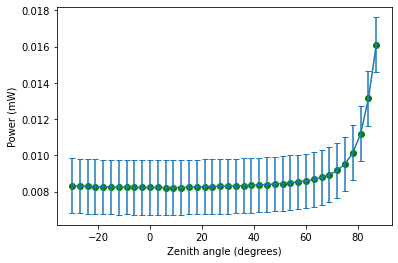

In [5]:
fig = figure()
frame = fig.add_subplot(1,1,1)
frame.scatter(ang_set1_masked,P_set1_masked, color='g')
frame.set_xlabel("Zenith angle (degrees)")
frame.errorbar(ang_set1_masked, P_set1_masked, yerr=P_std_dev_set1, capsize=3)
frame.set_ylabel("Power (mW)")
#frame.set_title("Power as a function of zenith angle graph dataset 1")
show()

[-30. -27. -24. -21. -18. -15. -12.  -9.  -6.  -3.   0.   3.   6.   9.
  12.  15.  18.  21.  24.  27.  30.  33.  36.  39.  42.  45.  48.  51.
  54.  57.  60.  63.  66.  69.  72.  75.  78.  81.  84.  87.]


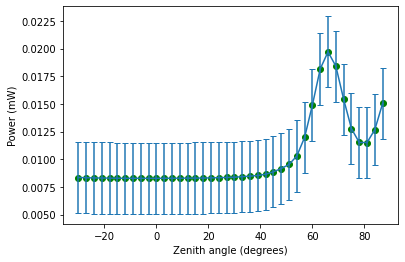

In [6]:
print(ang_set2_masked) 
fig = figure()
frame = fig.add_subplot(1,1,1)
frame.scatter(ang_set2_masked,P_set2_masked, color='g')
frame.errorbar(ang_set2_masked, P_set2_masked, yerr=P_std_dev_set2, capsize=3)
frame.set_xlabel("Zenith angle (degrees)")
frame.set_ylabel("Power (mW)")
#frame.set_title("Power as a function of zenith angle graph dataset 2")
show()

#### For dataset 2 only -- fit a Gaussian

[54. 57. 60. 63. 66. 69. 72. 75. 78.]
[0.01029292 0.01197661 0.01491092 0.01816574 0.01970583 0.01841538
 0.01542831 0.01276868 0.01151475]
Fitted parameters are: [9.63708940e-03 6.63448234e+01 5.36615777e+00 1.00493313e-02]
std dev Gaussian = 5.3661578 ± 0.3621199 deg


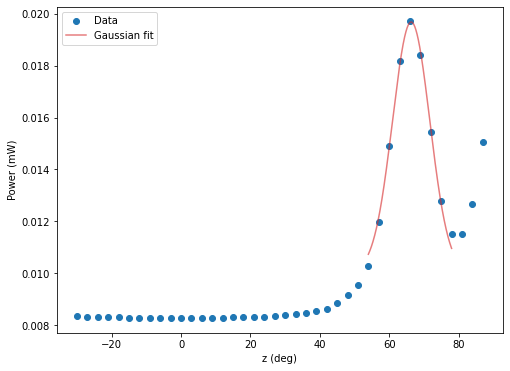

In [7]:
def gaussian(x, A, mu, sigma, C):
    return A * np.exp(-0.5*((x-mu)/sigma)**2) + C

## Estimate initial conditions for your parameters ##
A0 = 0.012
mu0 = 60
sigma0 = 5
C0 = np.median(P_set2_masked)

p0 = [A0, mu0, sigma0, C0]

#here i only want to fit a gaussian for part of the data that looks gaussian
#by trial and error of best-fitting gaussians, i think this is from z = 54 to 78

ang_set2_gaussian = ang_set2_masked[28:-3]
P_set2_gaussian = P_set2_masked[28:-3]
print(ang_set2_gaussian)
print(P_set2_gaussian)

## Fitting the data ##
popt_gauss, pcov_gauss = curve_fit(gaussian, ang_set2_gaussian, P_set2_gaussian, p0=p0)
print(f"Fitted parameters are: {popt_gauss}".format(*popt_gauss))

x_smooth = np.linspace(min(ang_set2_gaussian), max(ang_set2_gaussian), 1000)

p_err = np.sqrt(np.diag(pcov_gauss))
A_fit, mu_fit, sigma_fit, C_fit = popt_gauss
A_err, mu_err, sigma_err, C_err = p_err

print(f"std dev Gaussian = {sigma_fit:.7f} ± {sigma_err:.7f} deg")

fig, frame = plt.subplots(figsize=(8, 6))
frame.scatter(ang_set2_masked, P_set2_masked, label="Data", c='C0')
frame.plot(x_smooth, gaussian(x_smooth, *popt_gauss), label="Gaussian fit", c='C3', alpha=0.6)

#frame.set_title(f'Fitted Gaussian for satellite (dataset 2)')
frame.set_aspect('auto')
frame.set_xlabel("z (deg)")
frame.set_ylabel("Power (mW)")
frame.legend()

plt.show()

In [8]:
#now we compare to fwhm: https://statproofbook.github.io/P/norm-fwhm.html
fwhm_set2 = 2*np.sqrt(2*np.log(2)) * sigma_fit
print("FWHM of the Gaussian fitting: ", fwhm_set2) #in deg

FWHM of the Gaussian fitting:  12.636335878066806


In [9]:
fwhm_set2*(2.9168708 * 10**(-4))/fwhm_set2

0.00029168708

In [10]:
0.00029168708*3600

1.050073488

In [11]:
(sigma_err/sigma_fit) * fwhm_set2

0.8527272501629788

#### Step 1: Determine the y-factor to find $T_{rec}$

In [12]:
P_c_avg_set1 = (P_c1_set1+P_c2_set1)/2
P_h_avg_set1 = (P_h1_set1+P_h2_set1)/2
P_c_avg_set2 = (P_c1_set2+P_c2_set2)/2
P_h_avg_set2 = (P_h1_set2+P_h2_set2)/2

P_h_err_set1 = (1/np.sqrt(2))*np.sqrt((P_h1_set1-P_h_avg_set1)**2+(P_h2_set1-P_h_avg_set1)**2)
P_h_err_set2 = (1/np.sqrt(2))*np.sqrt((P_h1_set2-P_h_avg_set2)**2+(P_h2_set2-P_h_avg_set2)**2)
P_c_err_set1 = (1/np.sqrt(2))*np.sqrt((P_c1_set1-P_c_avg_set1)**2+(P_c2_set1-P_c_avg_set1)**2)
P_c_err_set2 = (1/np.sqrt(2))*np.sqrt((P_c1_set2-P_c_avg_set2)**2+(P_c2_set2-P_c_avg_set2)**2)

y_fact_set1 = P_h_avg_set1/P_c_avg_set1
y_fact_set2 = P_h_avg_set2/P_c_avg_set2

y_err_set1 = y_fact_set1*np.sqrt((P_h_err_set1/P_h_avg_set1)**2+(P_c_err_set1/P_c_avg_set1)**2)
y_err_set2 = y_fact_set2*np.sqrt((P_h_err_set2/P_h_avg_set2)**2+(P_c_err_set2/P_c_avg_set2)**2)

print(f"y-factor dataset 1 = {y_fact_set1:.7f} ± {y_err_set1:.7f} ")
print(f"y-factor dataset 2 = {y_fact_set2:.7f} ± {y_err_set2:.7f} ")

y-factor dataset 1 = 2.2284903 ± 0.0138998 
y-factor dataset 2 = 2.2164537 ± 0.0021351 


In [13]:
T_h = 275 #± 0.5 K
T_h_err = 0.5
T_atm = 275 #± 0.5 K
T_atm_err = 0.5
T_c = 77.36 #K, no error given but assume also ± 0.5?
T_c_err = 0.5

T_rec_set1 = (T_h - y_fact_set1*T_c)/(y_fact_set1 - 1)
T_rec_set2 = (T_h - y_fact_set2*T_c)/(y_fact_set2 - 1)

T_rec_set1_err = np.sqrt(((T_c-T_h)/(y_fact_set1-1)**2)**2 * y_err_set1**2 + (1/(y_fact_set1-1))**2 * T_h_err**2 + (-y_fact_set1/(y_fact_set1-1))**2 * T_c_err**2)
T_rec_set2_err = np.sqrt(((T_c-T_h)/(y_fact_set2-1)**2)**2 * y_err_set2**2 + (1/(y_fact_set2-1))**2 * T_h_err**2 + (-y_fact_set2/(y_fact_set2-1))**2 * T_c_err**2)


print(f"receiver temp from set 1 = {T_rec_set1:.7f} ± {T_rec_set1_err:.7f}")
print(f"receiver temp from set 2 = {T_rec_set2:.7f} ± {T_rec_set2_err:.7f}")

receiver temp from set 1 = 83.5203921 ± 2.0740631
receiver temp from set 2 = 85.1122734 ± 1.0393478


#### Step 2: Find G

In [14]:
bandwidth = 10**9 #in Hz
kb = 1.380649 * 10**(-23)
#convert to W from mW (to make kB have consistent units)
G_set1 = (P_h_avg_set1*10**(-3)-P_c_avg_set1*10**(-3))/(kb*bandwidth*(T_h-T_c))
#G_set1 = (P_h_avg_set1-P_c_avg_set1)/(kb*bandwidth*(T_h-T_c))
print(f"G_amp for dataset1 = {G_set1:.7f}")

G_set2 = (P_h_avg_set2*10**(-3)-P_c_avg_set2*10**(-3))/(kb*bandwidth*(T_h-T_c))
#G_set2 = (P_h_avg_set2-P_c_avg_set2)/(kb*bandwidth*(T_h-T_c))
print(f"G_amp for dataset2 = {G_set2:.7f}")

G_amp for dataset1 = 6527885.7430168
G_amp for dataset2 = 6502450.8048492


In [15]:
G_cal_set1 = kb*bandwidth*G_set1*10**3 #multiply by 10^3 to get the calibration in mW again

G_cal_set2 = kb*bandwidth*G_set2*10**3 #multiply by 10^3 to get the calibration in mW again
print("calibrated gain set 2: ", G_cal_set2)

G_cal_set1_err = np.sqrt((1/(T_h-T_c))**2 * P_h_err_set1**2 + (-1/(T_h-T_c))**2 * P_c_err_set1**2 + ((-P_h_avg_set1 + P_c_avg_set1)/(T_h-T_c)**2)**2 * T_h_err**2 + ((P_h_avg_set1-P_c_avg_set1)/(T_h-T_c)**2)**2 * T_c_err**2)
G_cal_set2_err = np.sqrt((1/(T_h-T_c))**2 * P_h_err_set2**2 + (-1/(T_h-T_c))**2 * P_c_err_set2**2 + ((-P_h_avg_set2 + P_c_avg_set2)/(T_h-T_c)**2)**2 * T_h_err**2 + ((P_h_avg_set2-P_c_avg_set2)/(T_h-T_c)**2)**2 * T_c_err**2)

print(f"calibrated gain set 1 = {G_cal_set1:.7f} ± {G_cal_set1_err:.7f}")
print(f"calibrated gain set 2 = {G_cal_set2:.7f} ± {G_cal_set2_err:.7f}")
err_G_amp_set2 = (G_cal_set2_err/G_cal_set2)*G_set2
print(f"G_amp error for set 2 = {err_G_amp_set2:.7f}")
err_G_amp_set1 = (G_cal_set1_err/G_cal_set1)*G_set1
print(f"G_amp error for set 1 = {err_G_amp_set1:.7f}")

calibrated gain set 2:  8.977602201264244e-05
calibrated gain set 1 = 0.0000901 ± 0.0000008
calibrated gain set 2 = 0.0000898 ± 0.0000004
G_amp error for set 2 = 25810.2413556
G_amp error for set 1 = 61494.0090834


#### Step 3: Find the total system temperature $T_{sys}$

$P_{out} = T_{sys} G_{cal}$

In [16]:
#T_sys also dep per zenith angle, like P_out
#P_out is in the code itself
T_sys_set1 = P_set1_masked/G_cal_set1
T_sys_set2 = P_set2_masked/G_cal_set2
 
#multiplying by T_sys_set1 makes it huge
T_sys_set1_err = T_sys_set1 * np.sqrt((P_std_dev_set1/P_set1_masked)**2 + (G_cal_set1_err/G_cal_set1)**2)
#print(f"T_sys set 1 = {T_sys_set1} ± {T_sys_set1_err}")

#### Step 4: Find the antenna temperature

T_sys = T_a + T_ground + T_rec

In [17]:
#-1.6 #ideally find the true value
#T_ground = 293
T_ground = 0
T_a_set1 = T_sys_set1 - T_ground - T_rec_set1
print(T_a_set1)
#print(T_a_set1)
T_a_set2 = T_sys_set2 - T_ground - T_rec_set2

T_a_set1_err = np.sqrt(T_sys_set1_err**2 + T_rec_set1_err**2)
#print(f"T_a for set 1 = {T_a_set1} ± {T_a_set1_err}")

[ 9.00745193  8.66943339  8.49235624  8.33159431  8.18657121  8.07117778
  7.98077697  7.98381937  7.89725155  7.83064724  7.83548948  7.81747017
  7.72663903  7.77765394  7.80148777  7.9880355   8.16194867  8.27539349
  8.37119297  8.45792155  8.5924416   8.72971582  8.91160209  9.14666113
  9.37827929  9.63069184  9.9219172  10.24994621 10.71510653 11.21518453
 11.91063606 12.83223333 14.03610161 15.72199294 18.30070283 22.24065523
 29.13939414 40.74451598 62.45653017 95.32656806]


#### Step 5: Find $T_{CMB}$

In [18]:
#tau_0 = 0.1 #need some initial guess
#we do curve fit with tau_0 and T_CMB as free params
#T_atm = 275 K

In [19]:
print(ang_set1_masked)

[-30. -27. -24. -21. -18. -15. -12.  -9.  -6.  -3.   0.   3.   6.   9.
  12.  15.  18.  21.  24.  27.  30.  33.  36.  39.  42.  45.  48.  51.
  54.  57.  60.  63.  66.  69.  72.  75.  78.  81.  84.  87.]


$tau_0$ = 0.0182433, T_CMB = 2.8903536
statistical uncertainty for tau_0: 0.0009014
statistical uncertainty for T_CMB: 0.2686584


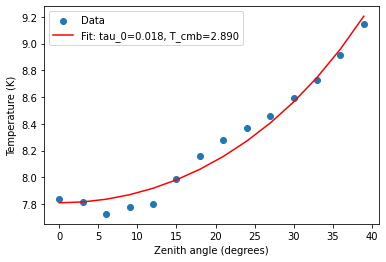

In [20]:
#do first for set 1 bc set 2 has satellite
def func(z, tau0, T_cmb):
    T_atm = 275
    #tau = tau_0 * (1/np.cos(z))
    z = np.deg2rad(z)
    T_a = T_cmb*np.exp(-tau0 * (1/np.cos(z))) + T_atm*(1-np.exp(-tau0 * (1/np.cos(z))))
    return T_a

ang_set1_fit = ang_set1_masked[10:24] #between 0 and 40
T_a_set1_fit = T_a_set1[10:24] #between 0 and 40

#ang_set1_fit = ang_set1_masked[10:23] #between 0 and 36
#T_a_set1_fit = T_a_set1[10:23] #between 0 and 36

#10:23 gives 2.716

#print(ang_set1_fit)
#print(T_a_set1_fit)

popt, pcov = curve_fit(func, ang_set1_fit, T_a_set1_fit, p0=[0.5,2.7])
tau_0, T_CMB = popt
T_CMB_err = np.sqrt(pcov[1,1]) #statistical error, smaller than through error propagation
tau_0_err = np.sqrt(pcov[0,0])
#if you put sigma=T_a_set1_err, absolute sigma=True then the error is on the scale of 3 K
                       
plt.scatter(ang_set1_fit, T_a_set1_fit, label='Data')
print(fr'$tau_0$ = {tau_0:.7f}, T_CMB = {T_CMB:.7f}')
print(f"statistical uncertainty for tau_0: {tau_0_err:.7f}")
print(f"statistical uncertainty for T_CMB: {T_CMB_err:.7f}")
plt.plot(ang_set1_fit, func(ang_set1_fit, *popt), 'r-', label='Fit: tau_0=%5.3f, T_cmb=%5.3f' % tuple(popt))
#plt.xlim(-30, 0)
#plt.title(r'Plot of $T_{A}$ as a function of zenith angle for dataset 1')
plt.ylabel('Temperature (K)')
plt.xlabel('Zenith angle (degrees)')
plt.legend()
plt.show()

In [21]:
#now we separately find the error propagation error
z = np.deg2rad(ang_set1_masked)
tau = tau_0 * (1/np.cos(z))
sigma_Tatm = 0.5 #assume
T_CMB_err_points = np.sqrt((np.exp(tau) * T_a_set1_err)**2 + ((1 - np.exp(tau)) * sigma_Tatm)**2)
#print(T_CMB_err_points)

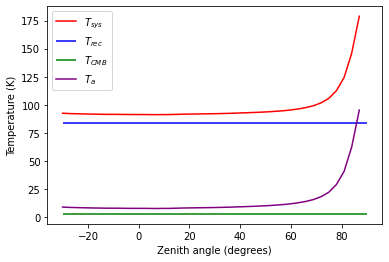

In [22]:
plt.plot(ang_set1_masked, T_sys_set1, label=r'$T_{sys}$', color='red')
plt.hlines(T_rec_set1, xmin=-30, xmax=90, label=r'$T_{rec}$', color='blue')
plt.hlines(T_CMB, xmin=-30, xmax=90, label=r'$T_{CMB}$', color='green')
plt.plot(ang_set1_masked, T_a_set1, label=r'$T_{a}$', color='purple')

#plt.title(r'Plot of temperatures as a function of zenith angle')
plt.ylabel('Temperature (K)')
plt.xlabel('Zenith angle (degrees)')
plt.legend()
plt.show()